In [ ]:
import pandas as pd

df=pd.read_csv("/content/Heart Disease.csv")
df.head()

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,No,16.60,Yes,No,No,3,30,No,Female,55-59,White,Yes,Yes,Very good,5.0,Yes,No,Yes
1,No,20.34,No,No,Yes,0,0,No,Female,80 or older,White,No,Yes,Very good,7.0,No,No,No
2,No,26.58,Yes,No,No,20,30,No,Male,65-69,White,Yes,Yes,Fair,8.0,Yes,No,No
3,No,24.21,No,No,No,0,0,No,Female,75-79,White,No,No,Good,6.0,No,No,Yes
4,No,23.71,No,No,No,28,0,Yes,Female,40-44,White,No,Yes,Very good,8.0,No,No,No


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319795 entries, 0 to 319794
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   HeartDisease      319795 non-null  object 
 1   BMI               319795 non-null  float64
 2   Smoking           319795 non-null  object 
 3   AlcoholDrinking   319795 non-null  object 
 4   Stroke            319795 non-null  object 
 5   PhysicalHealth    319795 non-null  int64  
 6   MentalHealth      319795 non-null  int64  
 7   DiffWalking       319795 non-null  object 
 8   Sex               319795 non-null  object 
 9   AgeCategory       319795 non-null  object 
 10  Race              319795 non-null  object 
 11  Diabetic          319795 non-null  object 
 12  PhysicalActivity  319795 non-null  object 
 13  GenHealth         319795 non-null  object 
 14  SleepTime         319795 non-null  int64  
 15  Asthma            319795 non-null  object 
 16  KidneyDisease     31

In [ ]:
median_sleeptime = df['SleepTime'].median()
df['SleepTime'] = df['SleepTime'].fillna(median_sleeptime)

print("Missing values in SleepTime after re-imputation:")
print(df['SleepTime'].isnull().sum())

Missing values in SleepTime after re-imputation:
0


In [ ]:
from sklearn.preprocessing import StandardScaler

# Identify numerical columns for scaling
# Exclude 'HeartDisease' as it's the target variable
# Exclude boolean columns as they are already binary
numerical_cols_for_scaling = [
    'BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime', 'AgeCategory', 'GenHealth'
]

# Initialize StandardScaler
scaler = StandardScaler()

# Apply scaling to the identified numerical columns
df[numerical_cols_for_scaling] = scaler.fit_transform(df[numerical_cols_for_scaling])

print("\nFirst 5 rows of the DataFrame after scaling numerical features:")
display(df.head())


First 5 rows of the DataFrame after scaling numerical features:


,HeartDisease,BMI,PhysicalHealth,MentalHealth,AgeCategory,GenHealth,SleepTime,Smoking_Yes,AlcoholDrinking_Yes,DiffWalking_Yes,Sex_Male,Diabetic_No,"Diabetic_No, borderline diabetes",Diabetic_Yes,Diabetic_Yes (during pregnancy),PhysicalActivity_Yes,Asthma_Yes,KidneyDisease_Yes,SkinCancer_Yes
0,0,-1.706176,1.175214,1.956361,0.120692,1.186194,-1.501857,True,False,False,False,False,False,True,False,True,True,False,True
1,0,-1.275197,-0.642683,-0.721571,1.510910,1.186194,-0.060385,False,False,False,False,True,False,False,False,True,False,False,False
2,0,-0.252645,1.897286,1.956361,0.676779,-0.787624,0.660351,True,False,False,True,False,False,True,False,True,True,False,False
3,0,-0.641018,-0.642683,-0.721571,1.232866,-0.129685,-0.781121,False,False,False,False,True,False,False,False,False,False,False,True
4,0,-0.722953,1.988863,-0.721571,-0.713438,1.186194,0.660351,False,False,True,False,True,False,False,False,True,False,False,False


In [ ]:
print("\nDataFrame info after all preprocessing steps:")
df.info()


DataFrame info after all preprocessing steps:
<class 'pandas.core.frame.DataFrame'>
Index: 84015 entries, 0 to 86304
Data columns (total 19 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   HeartDisease                      84015 non-null  int64  
 1   BMI                               84015 non-null  float64
 2   PhysicalHealth                    84015 non-null  float64
 3   MentalHealth                      84015 non-null  float64
 4   AgeCategory                       84015 non-null  float64
 5   GenHealth                         84015 non-null  float64
 6   SleepTime                         84015 non-null  float64
 7   Smoking_Yes                       84015 non-null  bool   
 8   AlcoholDrinking_Yes               84015 non-null  bool   
 9   DiffWalking_Yes                   84015 non-null  bool   
 10  Sex_Male                          84015 non-null  bool   
 11  Diabetic_No              

In [ ]:
df.drop("Race", axis=1, inplace=True)

In [ ]:
df.drop("Stroke", axis=1, inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(2290)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
HeartDisease,0
BMI,0
Smoking,0
AlcoholDrinking,0
PhysicalHealth,0
MentalHealth,0
DiffWalking,0
Sex,0
AgeCategory,0
Diabetic,0


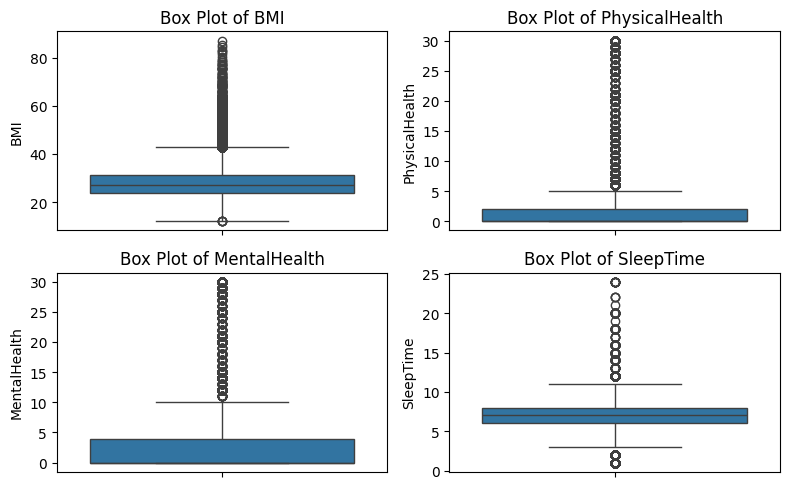

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Identify numerical columns for box plots
numerical_cols = ['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']

plt.figure(figsize=(8, 5))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 2, i) # Arrange plots in a 2x2 grid
    sns.boxplot(y=df[col])
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

### Visualizing Numerical Columns: Histograms and Box Plots

I will generate histograms and box plots for numerical columns to understand their distribution, central tendency, spread, and identify potential outliers.

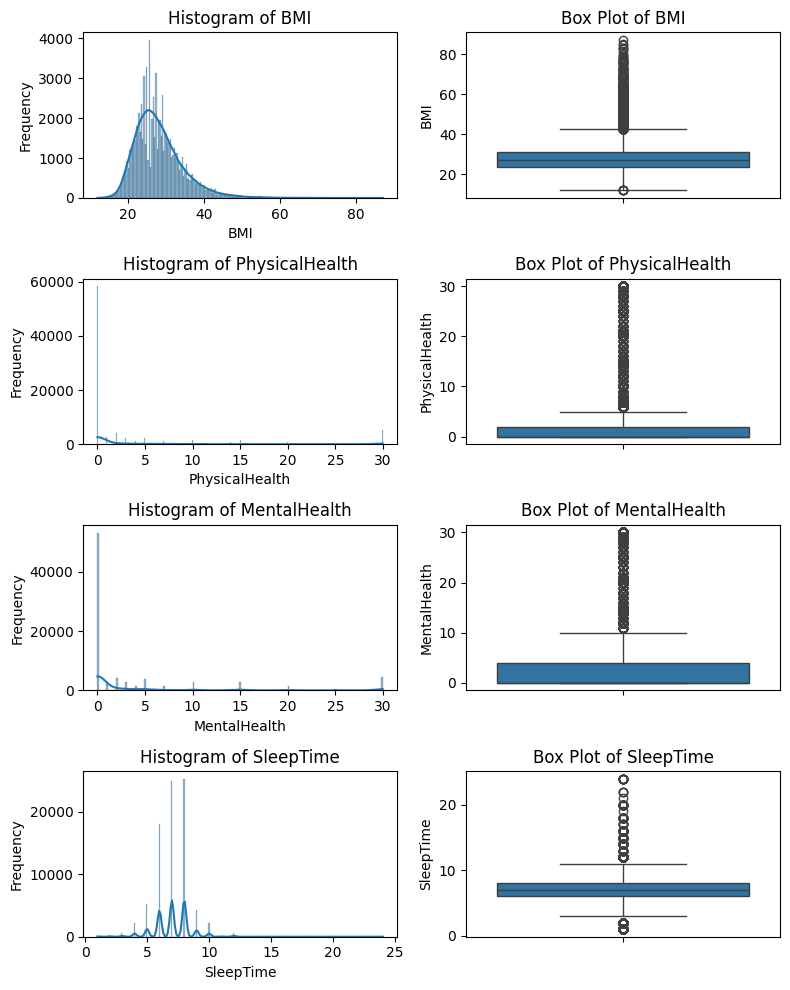

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Identify numerical columns based on df.info() and prior operations
numerical_cols = ['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']

# Create subplots for histograms and box plots for numerical columns
plt.figure(figsize=(8, 10))
for i, col in enumerate(numerical_cols):
    # Histogram
    plt.subplot(len(numerical_cols), 2, 2*i + 1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    # Box Plot
    plt.subplot(len(numerical_cols), 2, 2*i + 2)
    sns.boxplot(y=df[col])
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

### Visualizing Categorical Columns: Count Plots

For categorical columns, I will generate count plots to show the frequency of each category within the column.

/tmp/ipykernel_3759/3241232668.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')
/tmp/ipykernel_3759/3241232668.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')
/tmp/ipykernel_3759/3241232668.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')
/tmp/ipykernel_3759/3241232668.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set 

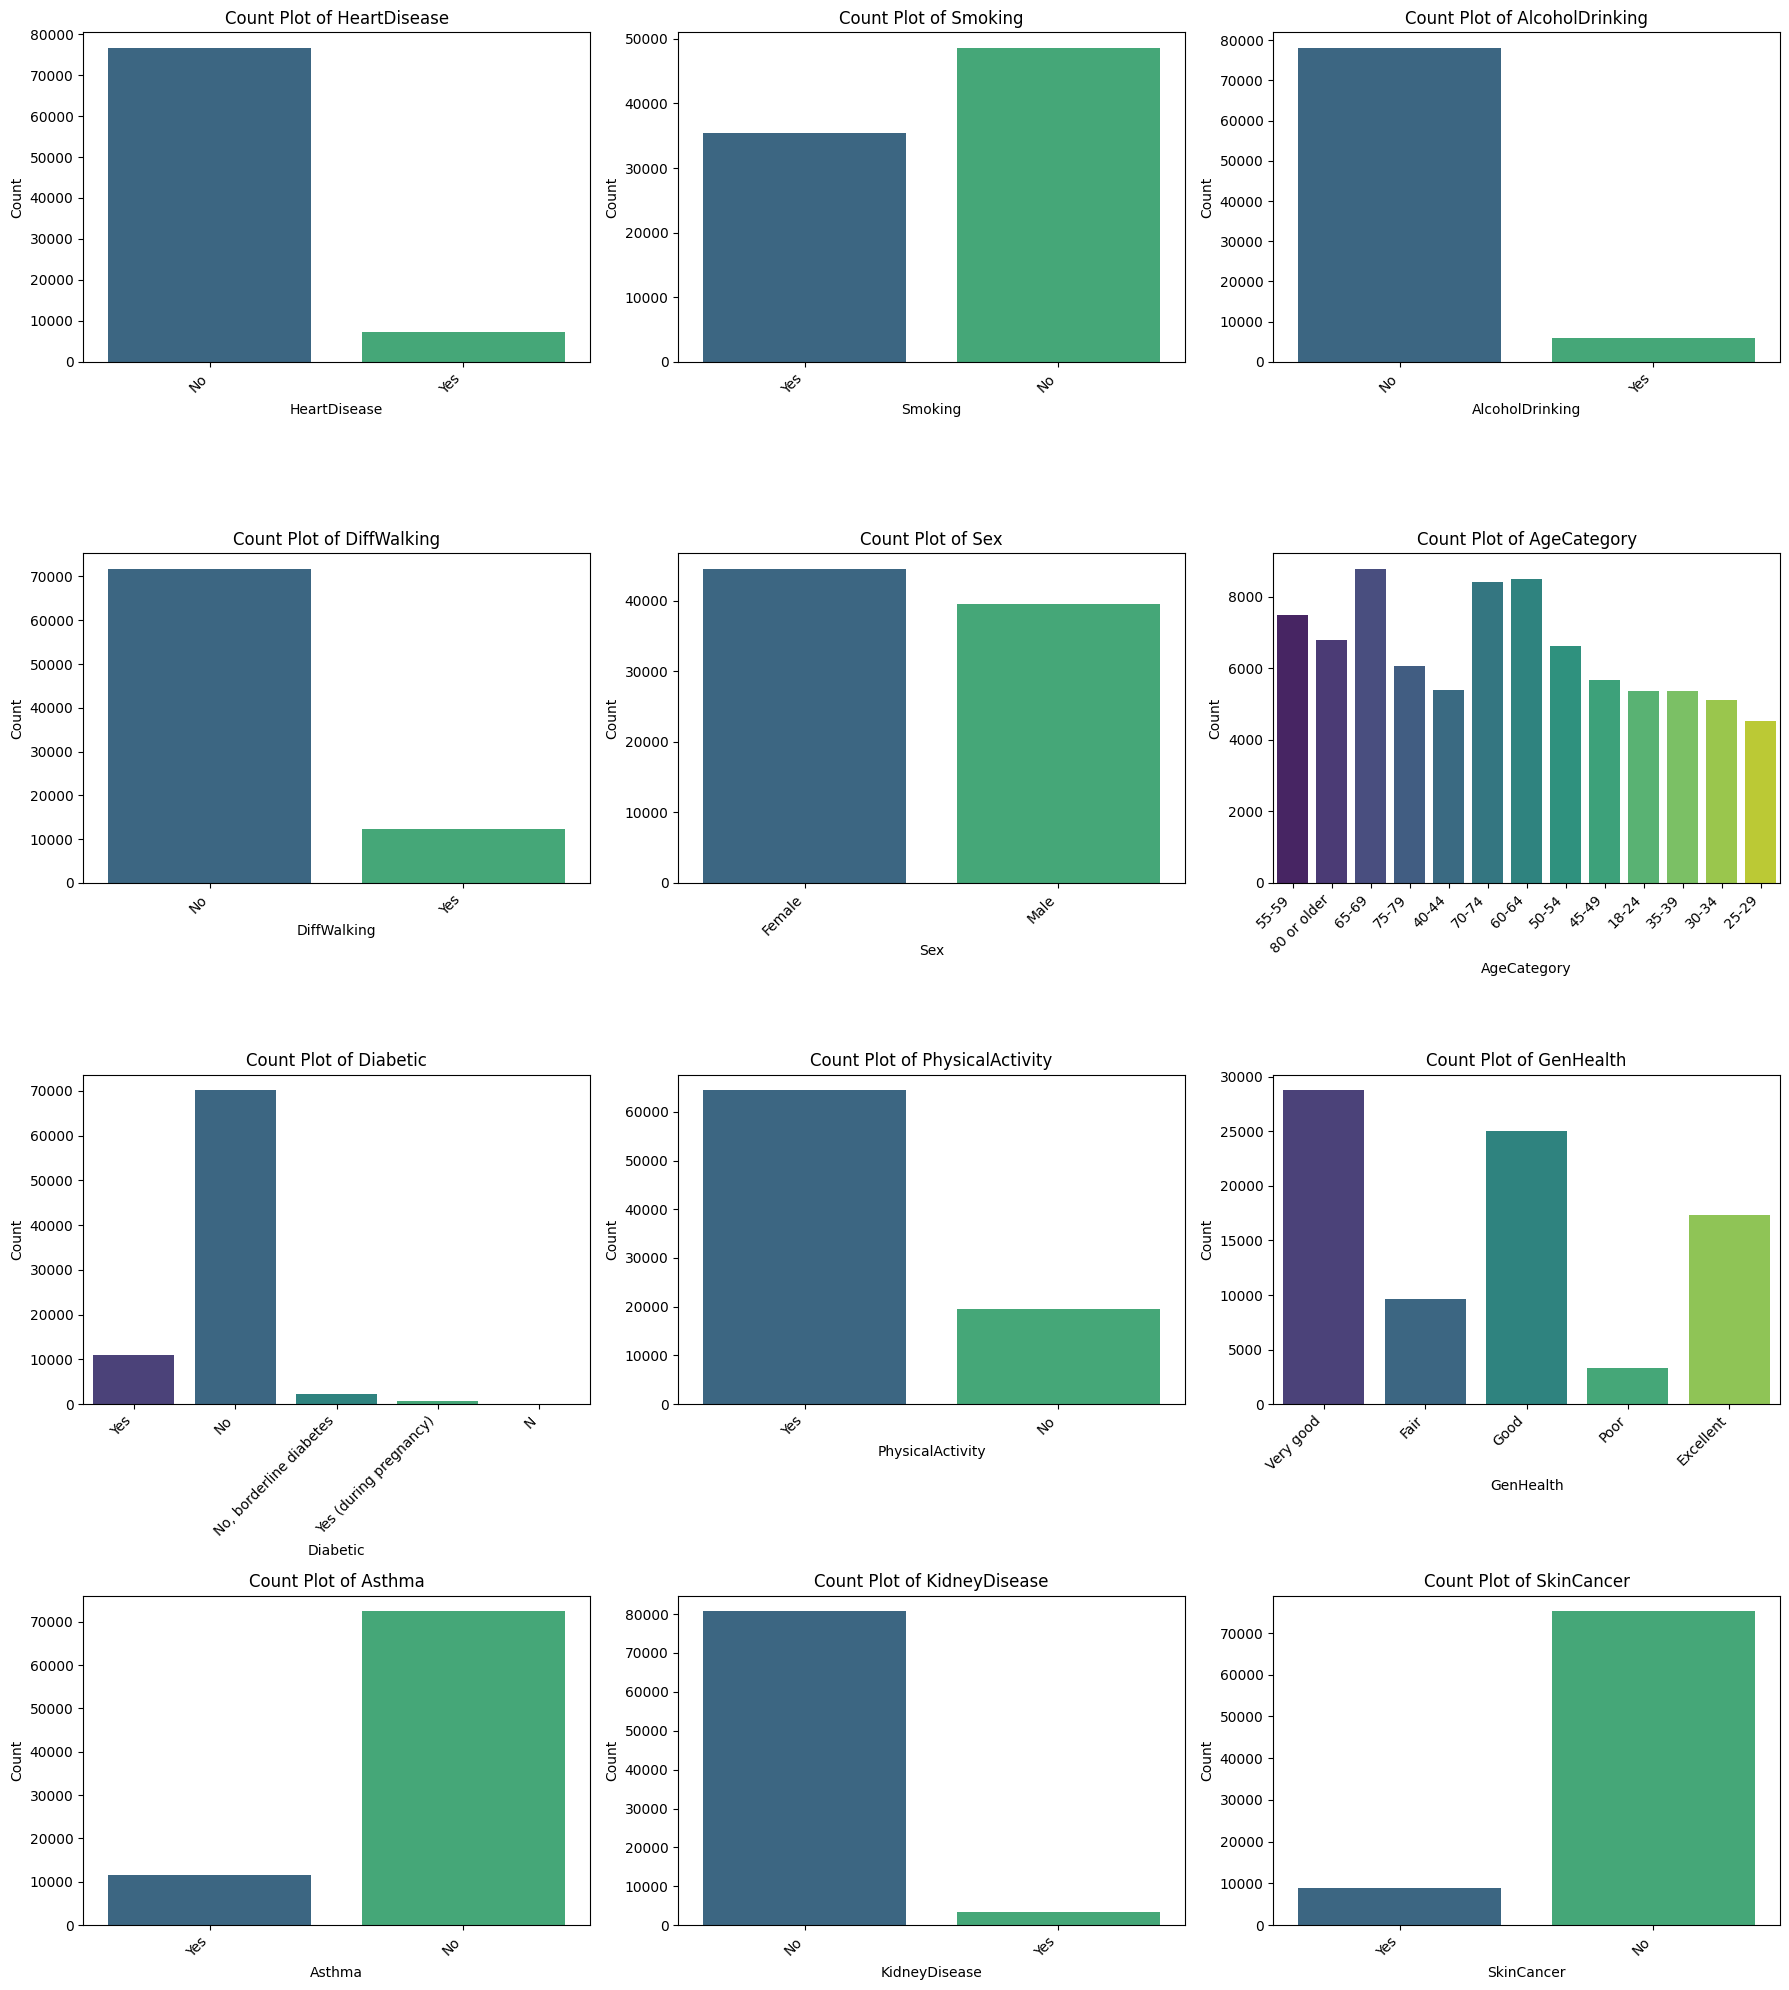

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Identify categorical columns
categorical_cols = [
    'HeartDisease', 'Smoking', 'AlcoholDrinking', 'DiffWalking', 'Sex',
    'AgeCategory', 'Diabetic', 'PhysicalActivity', 'GenHealth', 'Asthma',
    'KidneyDisease', 'SkinCancer'
]

# Determine the number of rows needed for subplots (e.g., 3 plots per row)
n_rows = (len(categorical_cols) + 2) // 3  # Ensures enough rows

plt.figure(figsize=(18, n_rows * 5))
for i, col in enumerate(categorical_cols, 1):
    plt.subplot(n_rows, 3, i)
    sns.countplot(data=df, x=col, palette='viridis')
    plt.title(f'Count Plot of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right') # Rotate labels for better readability

plt.tight_layout()
plt.show()

In [ ]:
def find_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower) | (df[column] > upper)]

    print(f"{column}: {len(outliers)} outliers")
    return outliers, lower, upper

In [ ]:
cols = ['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']

bounds = {}

for col in cols:
    outliers, lower, upper = find_outliers_iqr(df, col)
    bounds[col] = (lower, upper)

BMI: 2478 outliers
PhysicalHealth: 13206 outliers
MentalHealth: 10804 outliers
SleepTime: 1368 outliers


In [ ]:
for col in cols:
    lower, upper = bounds[col]

    print(f"\n🔎 {col} suspicious values:")
    print(df[(df[col] < lower) | (df[col] > upper)][col].head(10))


🔎 BMI suspicious values:
32     45.35
57     46.52
90     44.29
105    58.54
107    45.42
136    45.33
170    43.05
171    42.83
176    46.87
228    43.27
Name: BMI, dtype: float64

🔎 PhysicalHealth suspicious values:
2     20
4     28
5      6
6     15
10    30
13     7
25    30
26    21
32    30
35    10
Name: PhysicalHealth, dtype: int64

🔎 MentalHealth suspicious values:
0     30
2     30
14    30
17    30
22    15
23    30
25    30
78    30
84    15
96    14
Name: MentalHealth, dtype: int64

🔎 SleepTime suspicious values:
5      12.0
10     15.0
50     12.0
206    12.0
235     2.0
250     2.0
262    15.0
288     2.0
371    12.0
382    12.0
Name: SleepTime, dtype: float64


In [ ]:
import numpy as np

# BMI → Capping
df['BMI'] = np.clip(df['BMI'],
                    df['BMI'].quantile(0.01),
                    df['BMI'].quantile(0.99))

# PhysicalHealth → Log
df['PhysicalHealth'] = np.log1p(df['PhysicalHealth'])

# MentalHealth → Log
df['MentalHealth'] = np.log1p(df['MentalHealth'])

# SleepTime → Capping
df['SleepTime'] = np.clip(df['SleepTime'],
                          df['SleepTime'].quantile(0.01),
                          df['SleepTime'].quantile(0.99))

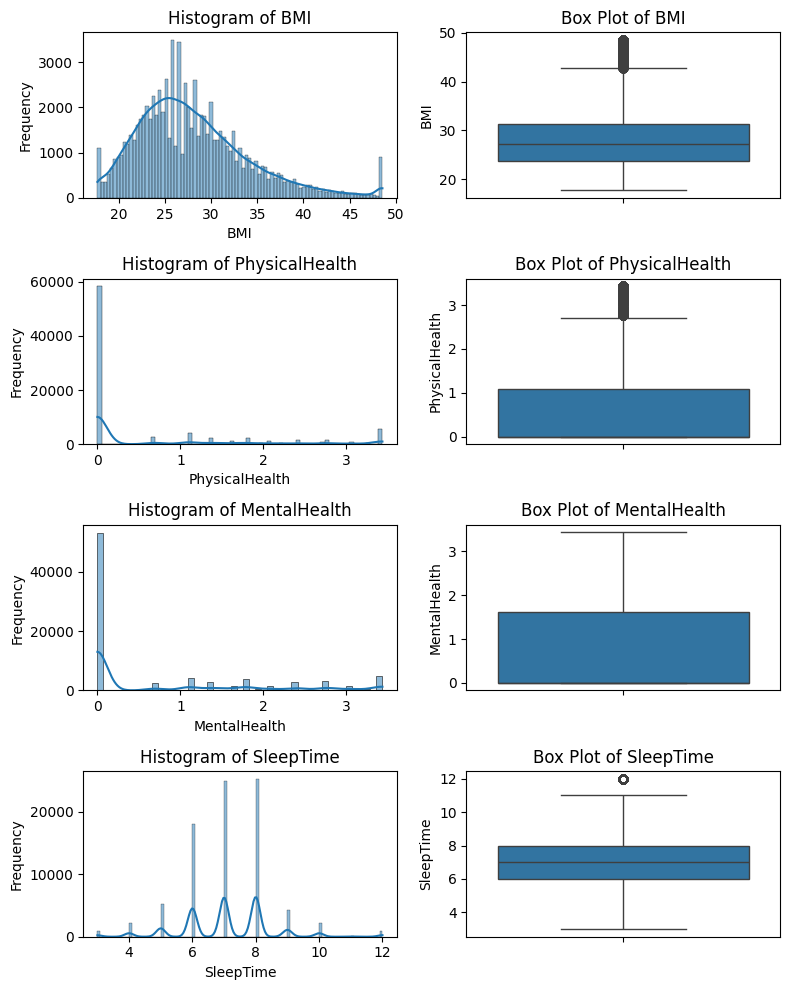

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Identify numerical columns based on df.info() and prior operations
numerical_cols = ['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']

# Create subplots for histograms and box plots for numerical columns
plt.figure(figsize=(8, 10))
for i, col in enumerate(numerical_cols):
    # Histogram
    plt.subplot(len(numerical_cols), 2, 2*i + 1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    # Box Plot
    plt.subplot(len(numerical_cols), 2, 2*i + 2)
    sns.boxplot(y=df[col])
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

In [ ]:
df['BMI'] = np.clip(df['BMI'],
                    df['BMI'].quantile(0.01),
                    df['BMI'].quantile(0.99))

In [ ]:
df['PhysicalHealth'] = np.log1p(df['PhysicalHealth'])

In [ ]:
df['SleepTime'] = np.clip(df['SleepTime'],
                          df['SleepTime'].quantile(0.01),
                          df['SleepTime'].quantile(0.99))

In [ ]:
df['BMI'] = np.clip(df['BMI'],
                    df['BMI'].quantile(0.01),
                    df['BMI'].quantile(0.99))

In [ ]:
df['SleepTime'] = np.clip(df['SleepTime'],
                          df['SleepTime'].quantile(0.01),
                          df['SleepTime'].quantile(0.99))

In [ ]:
# Capping BMI at the 99th percentile
bmi_99 = df['BMI'].quantile(0.99)
df['BMI'] = df['BMI'].clip(upper=bmi_99)

# Capping SleepTime (e.g., max 12 hours, min 3 hours)
df['SleepTime'] = df['SleepTime'].clip(lower=3, upper=12)

In [ ]:
import numpy as np

# Log(x+1) handles the 0s and reduces the skewness
df['PhysicalHealth'] = np.log1p(df['PhysicalHealth'])
df['MentalHealth'] = np.log1p(df['MentalHealth'])

In [ ]:
# Capping BMI at the 99th percentile
upper_bmi = df['BMI'].quantile(0.99)
df['BMI'] = df['BMI'].clip(upper=upper_bmi)

# Capping SleepTime at reasonable human limits (e.g., 2 to 12 hours)
df['SleepTime'] = df['SleepTime'].clip(lower=2, upper=12)

In [ ]:
# 1. Find the 99th percentile (only 1% of data is above this)
bmi_99 = df['BMI'].quantile(0.99)

# 2. "Clip" the data - anything above this value becomes this value
df['BMI'] = df['BMI'].clip(upper=bmi_99)

# 3. Verify
print(f"The new maximum BMI is: {df['BMI'].max()}")

The new maximum BMI is: 48.55


In [ ]:
# Capping SleepTime at 2 (min) and 12 (max)
df['SleepTime'] = df['SleepTime'].clip(lower=1, upper=18)

# Verify the results
print(f"New SleepTime Range: {df['SleepTime'].min()} to {df['SleepTime'].max()}")
print(f"Remaining SleepTime outliers: {((df['SleepTime'] < 1) | (df['SleepTime'] > 18)).sum()}")

New SleepTime Range: 3.0 to 12.0
Remaining SleepTime outliers: 0


In [ ]:
# Updating the clip range to 2 and 18
df['SleepTime'] = df['SleepTime'].clip(lower=2, upper=18)

# Verify the new range
print(f"Updated SleepTime Range: {df['SleepTime'].min()} to {df['SleepTime'].max()}")

Updated SleepTime Range: 3.0 to 12.0


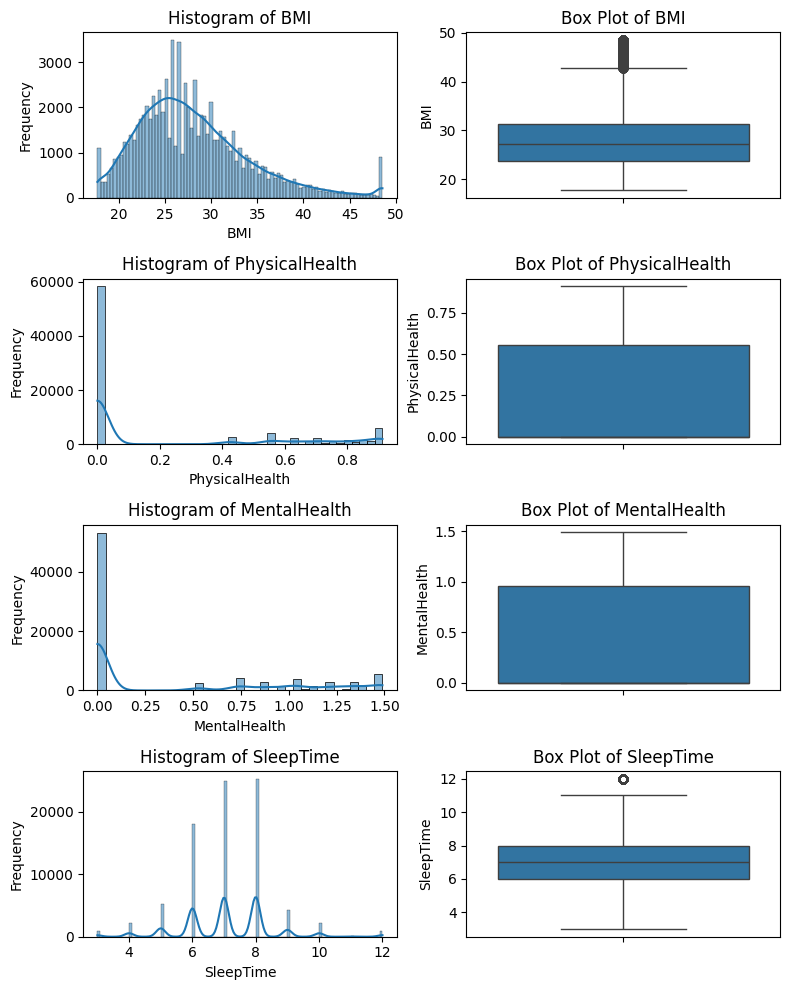

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Identify numerical columns based on df.info() and prior operations
numerical_cols = ['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']

# Create subplots for histograms and box plots for numerical columns
plt.figure(figsize=(8, 10))
for i, col in enumerate(numerical_cols):
    # Histogram
    plt.subplot(len(numerical_cols), 2, 2*i + 1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    # Box Plot
    plt.subplot(len(numerical_cols), 2, 2*i + 2)
    sns.boxplot(y=df[col])
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# Label Encoding for HeartDisease (target variable)
le = LabelEncoder()
df['HeartDisease'] = le.fit_transform(df['HeartDisease'])
print(f"HeartDisease mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# Label Encoding for Ordinal Features
ordinal_cols = ['GenHealth', 'AgeCategory']
for col in ordinal_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    print(f"{col} mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# One-Hot Encoding for Nominal Features
nominal_cols = ['Smoking', 'AlcoholDrinking', 'DiffWalking', 'Sex', 'Diabetic', 'PhysicalActivity', 'Asthma', 'KidneyDisease', 'SkinCancer']
df = pd.get_dummies(df, columns=nominal_cols, drop_first=True)

print("\nDataFrame info after encoding:")
df.info()

HeartDisease mapping: {'No': np.int64(0), 'Yes': np.int64(1)}
GenHealth mapping: {'Excellent': np.int64(0), 'Fair': np.int64(1), 'Good': np.int64(2), 'Poor': np.int64(3), 'Very good': np.int64(4), nan: np.int64(5)}
AgeCategory mapping: {'18-24': np.int64(0), '25-29': np.int64(1), '30-34': np.int64(2), '35-39': np.int64(3), '40-44': np.int64(4), '45-49': np.int64(5), '50-54': np.int64(6), '55-59': np.int64(7), '60-64': np.int64(8), '65-69': np.int64(9), '70-74': np.int64(10), '75-79': np.int64(11), '80 or older': np.int64(12)}

DataFrame info after encoding:
<class 'pandas.core.frame.DataFrame'>
Index: 84015 entries, 0 to 86304
Data columns (total 19 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   HeartDisease                      84015 non-null  int64  
 1   BMI                               84015 non-null  float64
 2   PhysicalHealth                    84015 non-null  float64
 3   MentalHealth

In [ ]:
print("\nFirst 5 rows of the DataFrame after encoding:")
display(df.head())


First 5 rows of the DataFrame after encoding:


,HeartDisease,BMI,PhysicalHealth,MentalHealth,AgeCategory,GenHealth,SleepTime,Smoking_Yes,AlcoholDrinking_Yes,DiffWalking_Yes,Sex_Male,Diabetic_No,"Diabetic_No, borderline diabetes",Diabetic_Yes,Diabetic_Yes (during pregnancy),PhysicalActivity_Yes,Asthma_Yes,KidneyDisease_Yes,SkinCancer_Yes
0,0,17.71,0.625800,1.489299,7,4,5.0,True,False,False,False,False,False,True,False,True,True,False,True
1,0,20.34,0.000000,0.000000,12,4,7.0,False,False,False,False,True,False,False,False,True,False,False,False
2,0,26.58,0.874370,1.489299,9,1,8.0,True,False,False,True,False,False,True,False,True,True,False,False
3,0,24.21,0.000000,0.000000,11,2,6.0,False,False,False,False,True,False,False,False,False,False,False,True
4,0,23.71,0.905894,0.000000,4,4,8.0,False,False,True,False,True,False,False,False,True,False,False,False


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# The original 'Diabetic' column no longer exists as it was one-hot encoded
# in a previous step (cell 9e85f4f5). This line will cause a KeyError.
# If you intended to modify the 'Diabetic' categories before one-hot encoding,
# this operation should be performed earlier in the preprocessing pipeline.
# # --- STEP 1: Final Categorical Cleaning ---
# # Grouping the small categories in 'Diabetic'
# df['Diabetic'] = df['Diabetic'].replace({
#     'No, borderline diabetes': 'No',
#     'Yes (during pregnancy)': 'Yes'
# })

# The 'GenHealth' column has already been label encoded in a previous step
# (cell 9e85f4f5). Re-mapping it here with a different scheme would corrupt the data.
# # --- STEP 2: Binary & Ordinal Encoding ---
# # We manually map these to ensure 'Excellent' is higher than 'Poor'
# gen_health_map = {'Poor': 0, 'Fair': 1, 'Good': 2, 'Very good': 3, 'Excellent': 4}
# df['GenHealth'] = df['GenHealth'].map(gen_health_map)

# Most of these 'binary_cols' have either been label encoded or one-hot encoded
# in a previous step (cell 9e85f4f5), or dropped ('Stroke' was dropped in s-lzYkqCKGqC).
# Applying LabelEncoder again on non-existent or already transformed columns will lead to errors or incorrect results.
# # Binary columns (Yes/No)
# binary_cols = ['HeartDisease', 'Smoking', 'AlcoholDrinking', 'Stroke', 'DiffWalking',
#                'Sex', 'PhysicalActivity', 'Asthma', 'KidneyDisease', 'SkinCancer', 'Diabetic']
#
# le = LabelEncoder()
# for col in binary_cols:
#     df[col] = le.fit_transform(df[col]) # Yes/Male/etc becomes 1, No/Female becomes 0

# The 'Race' column was dropped in a previous step (cell m4hugR8bJ8AD).
# The 'AgeCategory' column has already been label encoded in a previous step (cell 9e85f4f5).
# Applying get_dummies on a numeric 'AgeCategory' or a non-existent 'Race' will cause errors.
# # --- STEP 3: Nominal Encoding (One-Hot) ---
# # For 'Race' and 'AgeCategory' (if you don't want to rank age)
# df_final = pd.get_dummies(df, columns=['Race', 'AgeCategory'], drop_first=True)

# As encoding steps have already been performed in previous cells,
# the DataFrame `df` is already largely processed.
# We will print the dtypes value counts of the current `df` to show its state.
print(df.dtypes.value_counts())

bool       12
float64     6
int64       1
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# 1. Define Features (X) and Target (y)
# Replace 'HeartDisease' with the exact name of your target column
X = df.drop('HeartDisease', axis=1)
y = df['HeartDisease']

# 2. Perform the Stratified Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,      # This is the most important line for unbalanced data!
    random_state=42  # Keeps results consistent for your project
)

# 3. Verify the counts
print(f"Total Rows: {len(df)}")
print(f"Training Rows: {len(X_train)} (Check: {y_train.sum()} 'Yes' cases)")
print(f"Testing Rows: {len(X_test)} (Check: {y_test.sum()} 'Yes' cases)")

Total Rows: 84015
Training Rows: 67212 (Check: 5910 'Yes' cases)
Testing Rows: 16803 (Check: 1478 'Yes' cases)


In [ ]:
from imblearn.over_sampling import SMOTE

# 1. Initialize SMOTE
smote = SMOTE(random_state=42)

# 2. Resample the TRAINING data only
# We keep X_test and y_test separate and untouched!
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

# 3. Verify the new balance
print(f"New Training 'Yes' cases: {y_train_balanced.sum()}")
print(f"New Training 'No' cases: {(y_train_balanced == 0).sum()}")

New Training 'Yes' cases: 61302
New Training 'No' cases: 61302


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# 1. Define the Architecture
model = Sequential([
    # Input layer + First hidden layer
    Dense(32, activation='relu', input_shape=(X_train_balanced.shape[1],)),
    Dropout(0.2), # Prevents overfitting by "turning off" some neurons

    # Second hidden layer
    Dense(16, activation='relu'),

    # Output layer (Binary)
    Dense(1, activation='sigmoid')
])

# 2. Compile the Model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 3. Setup Early Stopping (as we discussed!)
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# 4. Train the Model
history = model.fit(
    X_train_balanced, y_train_balanced,
    validation_data=(X_test, y_test), # Validate on the "Real World" imbalanced data
    epochs=100,
    batch_size=32,
    callbacks=[early_stop]
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
3832/3832 ━━━━━━━━━━━━━━━━━━━━ 16s 3ms/step - accuracy: 0.7632 - loss: 0.4946 - val_accuracy: 0.7249 - val_loss: 0.5086
Epoch 2/100
3832/3832 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.7754 - loss: 0.4761 - val_accuracy: 0.7224 - val_loss: 0.4966
Epoch 3/100
3832/3832 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.7797 - loss: 0.4696 - val_accuracy: 0.7485 - val_loss: 0.4626
Epoch 4/100
3832/3832 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.7821 - loss: 0.4676 - val_accuracy: 0.7458 - val_loss: 0.4660
Epoch 5/100
3832/3832 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.7823 - loss: 0.4647 - val_accuracy: 0.7354 - val_loss: 0.4811
Epoch 6/100
3832/3832 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.7838 - loss: 0.4630 - val_accuracy: 0.7393 - val_loss: 0.4711
Epoch 7/100
3832/3832 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.7848 - loss: 0.4612 - val_accuracy: 0.7506 - val_loss: 0.4621
Epoch 8/100
3832/3832 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.7856 -

526/526 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
--- Classification Report ---
              precision    recall  f1-score   support

           0       0.96      0.78      0.86     15325
           1       0.23      0.69      0.35      1478

    accuracy                           0.77     16803
   macro avg       0.60      0.74      0.60     16803
weighted avg       0.90      0.77      0.82     16803



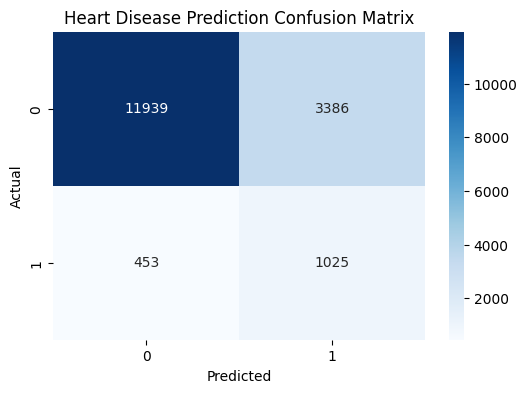

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Get predictions (probabilities)
y_pred_prob = model.predict(X_test)

# 2. Convert probabilities to 0 or 1 (Threshold = 0.5)
y_pred = (y_pred_prob > 0.5).astype(int)

# 3. Print the Report
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

# 4. Plot the Confusion Matrix
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Heart Disease Prediction Confusion Matrix')
plt.show()

In [ ]:
import pandas as pd

# Create a DataFrame for comparison
comparison_df = pd.DataFrame({
    'Actual': y_test.reset_index(drop=True),
    'Predicted': y_pred.flatten()
})

# Display the first 100 results
display(comparison_df.head(100))

,Actual,Predicted
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
95,0,0
96,0,0
97,0,0
98,0,0


In [ ]:
actual_yes_df = comparison_df[comparison_df['Actual'] == 1]
display(actual_yes_df.head(100))

,Actual,Predicted
37,1,1
50,1,1
73,1,0
83,1,1
87,1,0
...,...,...
1020,1,1
1024,1,1
1034,1,0
1062,1,0
